# Reproduction of: El-Batrawy et al., "High-Performance Heart Disease Prediction
Through Soft Voting Ensemble" (ETASR 16(3), 2026).

The paper publishes no code, so this follows the methodology section:
  - Kaggle "Heart Disease Data for Health Research" (oktayrdeki/heart-disease)
  - imputation -> one-hot/label encoding -> StandardScaler
  - stratified 80/20 split, random oversampling on training data only
  - SVM, MLP, Extra Trees tuned by grid search with 5-fold CV (Table I values)
  - soft voting over the three tuned models
  - metrics: accuracy, precision, recall, F1, ROC-AUC, ROC curves

In [4]:
%pip install numpy pandas scikit-learn imbalanced-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 9.8 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 18.0 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 19.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 20.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 16.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 25.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 20.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [imbalanced-learn][imbalanced-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

Matplotlib is building the font cache; this may take a moment.


Data Loading

In [7]:
# False = leak-free (oversample inside training folds only).
# True = oversample before the split, which the paper's Fig. 2 seems to do.
OVERSAMPLE_BEFORE_SPLIT = True

heart_disease_K = pd.read_csv("heart_disease_Kaggle.csv")
print(heart_disease_K.shape)
heart_disease_K.head()

(10000, 21)


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


Target, Features, and Colum Types

In [8]:
heart_disease_K = heart_disease_K.dropna(subset=["Heart Disease Status"])
y = (heart_disease_K["Heart Disease Status"].astype(str).str.strip().str.lower() == "yes").astype(int)
X = heart_disease_K.drop(columns=["Heart Disease Status"])

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(len(num_cols), "numeric,", len(cat_cols), "categorical")
print(y.value_counts())

9 numeric, 11 categorical
Heart Disease Status
0    8000
1    2000
Name: count, dtype: int64


# Train Test Split & Oversampling

80/20 split

Keeps the same Yes/No ratio in both parts

Oversampler: duplicates minority class (heart disease = Yes) until classes are balanced

- True: the whole dataset is oversampled before the split. Duplicated rows end up in both train and test.

- False: Oversampling is built into pipeline and runs only on training data. (use in my implementation)


In [9]:
if OVERSAMPLE_BEFORE_SPLIT:
    X, y = RandomOverSampler(random_state=42).fit_resample(X, y)
    oversampler = "passthrough"
else:
    oversampler = RandomOverSampler(random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(12800, 20) (3200, 20)


# Preprocessing Pipeline

Numeric Columns: Fills missin values with median. Then standardizes to mean 0 and standard deviation 1.

Categorical Columns: Fill missing values with most common value. One hot encode.

Make_pipe: Chains preprocessing, then oversampling, then classifier becomes one object.

In [10]:
def make_preprocessor():
    num = SkPipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())])
    cat = SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

def make_pipe(clf):
    return ImbPipeline([("prep", make_preprocessor()),
                        ("ros", oversampler),
                        ("clf", clf)])

Grid Search for each Base Model

Hyperparameters: tuned with grid search & 5-fold cross-validation

SVM: RBF kernel with probability=True for soft voting

MLP: Relu Activation & adaptive learning rate

Extra Trees: randomized trees

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "SVM": (SVC(kernel="rbf", probability=True, random_state=42),
            {"clf__C": [1, 10], "clf__gamma": [0.01, 0.1]}),
    "MLP": (MLPClassifier(activation="relu", max_iter=500, random_state=42),
            {"clf__alpha": [1e-4, 1e-3],
             "clf__learning_rate": ["adaptive"],
             "clf__hidden_layer_sizes": [(64, 32), (128, 64)]}),
    "Extra Trees": (ExtraTreesClassifier(random_state=42, n_jobs=-1),
                    {"clf__n_estimators": [100, 200],
                     "clf__max_depth": [10, 20],
                     "clf__min_samples_leaf": [1, 3]}),
}

tuned = {}
for name, (clf, grid) in candidates.items():
    gs = GridSearchCV(make_pipe(clf), grid, cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name}: {gs.best_params_}, CV F1 = {gs.best_score_:.4f}")

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.1

SVM: {'clf__C': 10, 'clf__gamma': 0.1}, CV F1 = 0.8745


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iteration

MLP: {'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (128, 64), 'clf__learning_rate': 'adaptive'}, CV F1 = 0.8546


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Extra Trees: {'clf__max_depth': 20, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}, CV F1 = 0.9541


# Soft Voting Ensemble
Combines the 3 tuned models:
- Model outputs probability for each class
- Ensemble averages those probabilities
- Then predicts class with highest average

In [12]:
voter = VotingClassifier(
    estimators=[("svm", tuned["SVM"]), ("mlp", tuned["MLP"]),
                ("et", tuned["Extra Trees"])],
    voting="soft", n_jobs=-1)
voter.fit(X_train, y_train)
tuned["Soft Voting"] = voter

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


# Evaluate on Test Set
- Turns predicted probalities into class labels at a 0.5 threshold
- Computes:
  - accuracy
  - Precision
  - Recall
  - F1
  - ROC-AUC

In [13]:
rows = []
roc_data = {}
for name, model in tuned.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"Method": name,
                 "Accuracy": 100 * accuracy_score(y_test, pred),
                 "Precision": 100 * precision_score(y_test, pred),
                 "Recall": 100 * recall_score(y_test, pred),
                 "F1": 100 * f1_score(y_test, pred),
                 "ROC-AUC": 100 * roc_auc_score(y_test, proba)})
    roc_data[name] = (roc_curve(y_test, proba), roc_auc_score(y_test, proba))

results = pd.DataFrame(rows).round(2)
results

,Method,Accuracy,Precision,Recall,F1,ROC-AUC
0,SVM,94.28,92.71,96.12,94.38,97.42
1,MLP,87.59,81.64,97.00,88.66,91.30
2,Extra Trees,97.88,99.80,95.94,97.83,97.96
3,Soft Voting,93.97,92.05,96.25,94.10,98.09


ROC Curves & Accuracy Chart

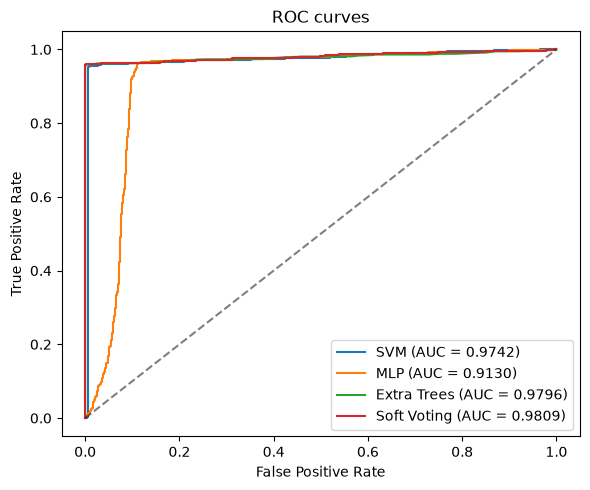

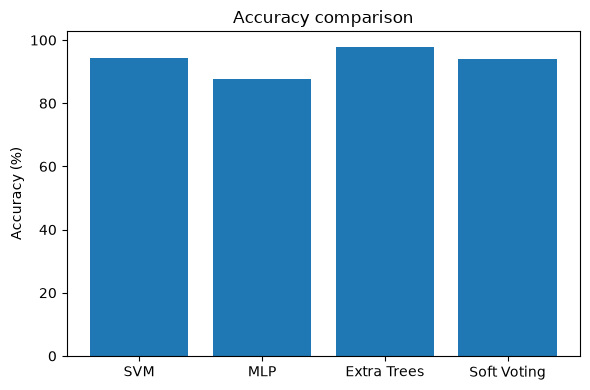

In [14]:
plt.figure(figsize=(6, 5))
for name, ((fpr, tpr, _), auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(results["Method"], results["Accuracy"])
plt.ylabel("Accuracy (%)")
plt.title("Accuracy comparison")
plt.tight_layout()
plt.show()